# Final Assignment Tutorial — Telecom

This notebook is a reference walkthrough for the GCI World 2026 Winter final assignment.
The dataset comes from **Company A**, an anonymous telecommunications service provider, and contains historical customer information across two linked tables (`Client.csv`, `Record.csv`).

Your task is to analyze this data, build a machine learning model whose output supports a concrete business proposal — not to build the best possible model.

**What this notebook covers:**

1. Market context and business problem definition.
2. Loading, validating, and merging the customer datasets.
3. Exploratory Data Analysis (EDA).
4. Feature engineering and data quality checks.
5. Train/validation/test splitting and preprocessing.
6. Comparing multiple machine learning models.
7. Model evaluation and feature importance.
8. Customer retention strategy and financial impact simulation.

The objective is to identify customers at risk of churn and use the model's predictions to support a measurable customer retention proposal.

---

## 1.Introduction & Market Analysis


Company A is an anonymous wireless telecommunications operator. The provided dataset contains approximately 100,000 customer records across two linked tables.

For this project, we assume that the company needs a data-driven approach to identify customers who may leave its services and prioritize retention activities. The company's actual internal machine learning capabilities should be confirmed with its management.

Customer retention is an important business problem for telecommunications operators. However, its financial importance and the main drivers of churn should be supported by evidence from the selected market.

This project will investigate the following hypotheses:

- Customer retention activities may help reduce revenue lost through customer churn.
- Changes in customer usage and billing patterns may be associated with churn.
- Equipment age and service-quality indicators may help identify customers who need attention.

These hypotheses will be investigated using the provided dataset and supported by recent, credible market references in the final proposal.

---

## 2.Setup and Data Loading


### 2.1 Import libraries

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)

**IMPORTANT**:<br>
Change the path in the `%cd` command below to match the folder where this notebook is saved on Google Drive by **replacing "WhereThisNotebookIsLocated" with your actual folder path**.

Example:
- You uploaded `Final Assignment` folder directly under MyDrive (the default folder when you open Google Drive)
    - Change to "/<wbr>content/drive/MyDrive/Final Assignment"

You can easily locate your notebook's directory by:
1. Open the Files panel on the left side of Colab
2. Navigate through the "drive" and "MyDrive" folders until you find your notebook's folders
3. Click the more actions icon (three vertical dots, $\vdots$) next to the folder name
4. Select the option "Copy path"

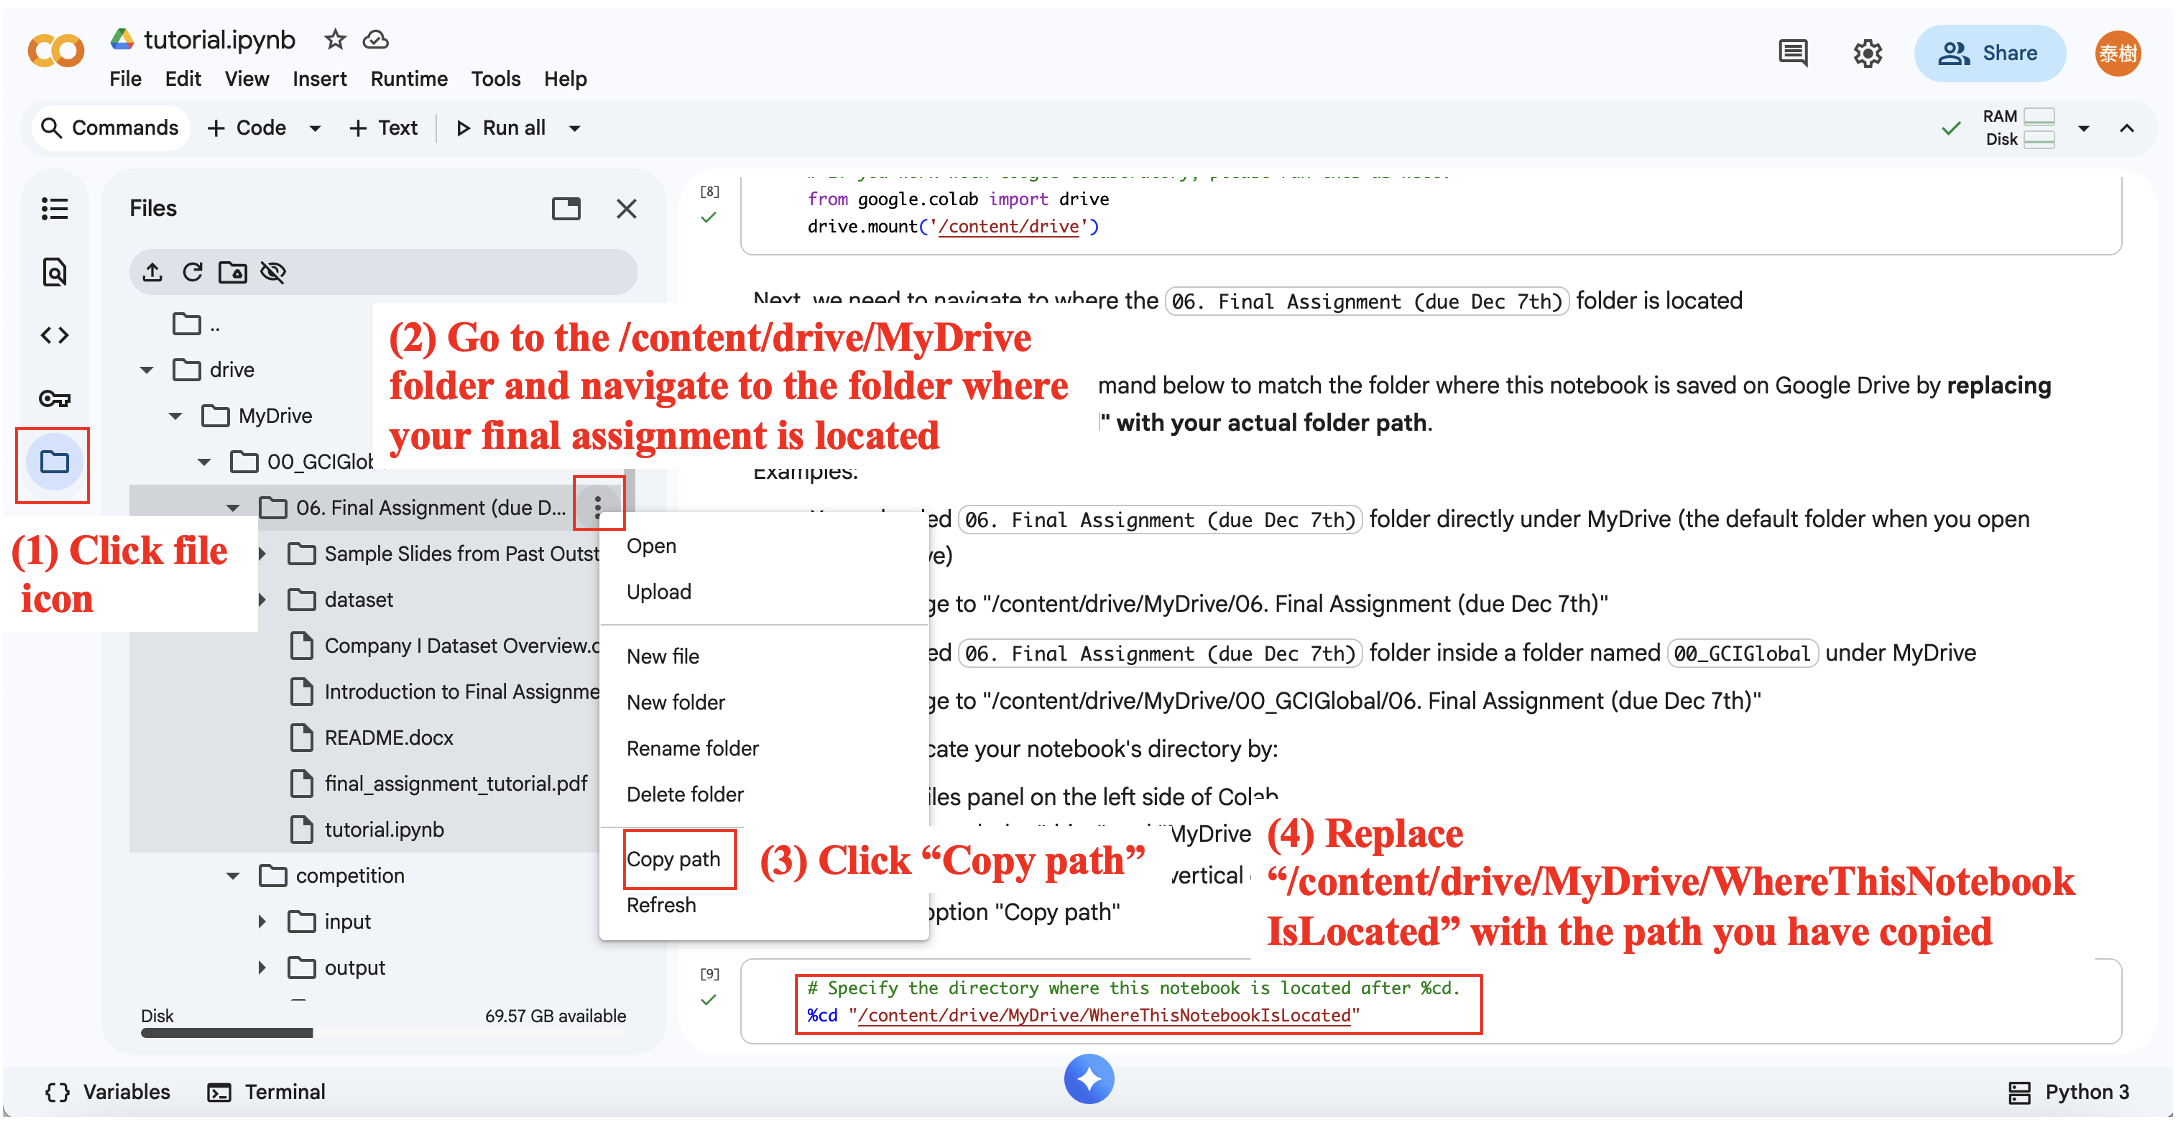

### 2.2 Connect to Google Drive

If you are running this notebook on Google Colab, mount your Drive and `cd` into the folder that contains the dataset.


In [76]:
from google.colab import drive
drive.mount('/content/drive')
#%cd "/content/drive/MyDrive/WhereThisNotebookIsLocated"
%cd "/content/drive/MyDrive/GCI2026/Final_Assignment"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/GCI2026/Final_Assignment


### 2.3 Load the two source tables

The dataset is split across two files:

| File | Granularity | Contents |
|---|---|---|
| `Client.csv` | one row per customer | account-level info: tenure, plan, demographics, equipment |
| `Record.csv` | one row per customer | mean monthly usage, billing, and call-quality metrics, plus the `churn` target |

Both tables share a `Customer_ID` column, which we use to join them into a single analysis table.


In [77]:
import os
from pathlib import Path

current_dir = Path(os.getcwd())
client_path = current_dir / "telecom" / "Client.csv"
record_path = current_dir / "telecom" / "Record.csv"

for p in (client_path, record_path):
    print(f"{'OK ' if p.exists() else 'MISSING '} {p}")

OK  /content/drive/MyDrive/GCI2026/Final_Assignment/telecom/Client.csv
OK  /content/drive/MyDrive/GCI2026/Final_Assignment/telecom/Record.csv


In [78]:
client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

print(f"Client: {client.shape}")
print(f"Record: {record.shape}")

Client: (100000, 50)
Record: (100000, 51)


In [79]:
# Merge on Customer_ID. Both tables have one row per customer, so this is a 1:1 join.
df = record.merge(client, on='Customer_ID', how='inner')
print(f"Merged: {df.shape}")
df.head()


Merged: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


---

## 3.Exploratory Data Analysis

Before modeling, three questions need answers:

1. **How big and structured is the data?** Rows, columns, dtypes.
2. **Where is the data incomplete or unreliable?**
3. **What does the target variable look like?**

Each answer constrains the next step. The shape and types tell us what preprocessing is required. The missingness tells us which columns may need to be dropped, imputed, or treated specially. The target distribution tells us which metrics will be meaningful.

EDA is also where the proposal starts to take shape — the patterns you see now become candidate signals for the model and anchors for the story your proposal will tell. The visualizations in this tutorial are intentionally minimal — just enough to make a point; for your proposal slides, you will want to polish them.

### 3.1 Shape and types

`df.info(verbose=False)` reports total rows, total columns, the count of columns of each dtype, and memory use. Two things to read from the output:

- **Dataset size.** Small enough to keep in pandas — no chunking needed.
- **Dtype mix.** Some columns may be stored as `object` (text). Most machine learning models can only learn from numbers, so any text columns will need to be converted to numeric form before modeling.

In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 100 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   rev_Mean          99643 non-null   float64
 1   mou_Mean          99643 non-null   float64
 2   totmrc_Mean       99643 non-null   float64
 3   da_Mean           99643 non-null   float64
 4   ovrmou_Mean       99643 non-null   float64
 5   ovrrev_Mean       99643 non-null   float64
 6   vceovr_Mean       99643 non-null   float64
 7   datovr_Mean       99643 non-null   float64
 8   roam_Mean         99643 non-null   float64
 9   change_mou        99109 non-null   float64
 10  change_rev        99109 non-null   float64
 11  drop_vce_Mean     100000 non-null  float64
 12  drop_dat_Mean     100000 non-null  float64
 13  blck_vce_Mean     100000 non-null  float64
 14  blck_dat_Mean     100000 non-null  float64
 15  unan_vce_Mean     100000 non-null  float64
 16  unan_dat_Mean     10

### 3.2 Missing values

A column that is mostly missing carries little signal — dropping it is often cleaner than trying to impute. We count the missing values in each column, take the 20 worst, and plot them.

numbcars            49366
dwllsize            38308
HHstatin            37923
ownrent             33706
dwlltype            31909
lor                 30190
income              25436
adults              23019
infobase            22079
hnd_webcap          10189
prizm_social_one     7388
avg6mou              2839
avg6qty              2839
avg6rev              2839
truck                1732
rv                   1732
kid11_15             1732
kid16_17             1732
marital              1732
forgntvl             1732
creditcd             1732
kid0_2               1732
kid3_5               1732
kid6_10              1732
ethnic               1732
change_mou            891
change_rev            891
hnd_price             847
da_Mean               357
totmrc_Mean           357
ovrmou_Mean           357
ovrrev_Mean           357
datovr_Mean           357
vceovr_Mean           357
rev_Mean              357
mou_Mean              357
roam_Mean             357
area                   40
refurb_new  

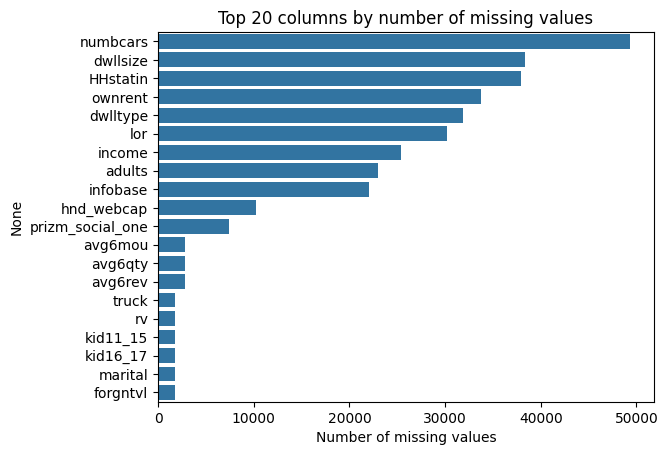

In [81]:
# Count of missing values per column
missing_counts = df.isna().sum()
print(missing_counts.sort_values(ascending=False))

# Take the 20 columns with the most missing values
top_missing = missing_counts.sort_values(ascending=False).head(20)

# Plot
sns.barplot(x=top_missing.values, y=top_missing.index)
plt.xlabel('Number of missing values')
plt.title('Top 20 columns by number of missing values')
plt.show()

The target variable is `churn`, which indicates whether a customer left the company 31–60 days after the observation date.

Before training, we must inspect the target distribution.

Class balance helps us understand whether accuracy alone is appropriate. However, accuracy should always be combined with other metrics such as precision, recall, F1-score, ROC-AUC, and PR-AUC.

churn
0    50438
1    49562
Name: count, dtype: int64

churn
0    0.50438
1    0.49562
Name: proportion, dtype: float64


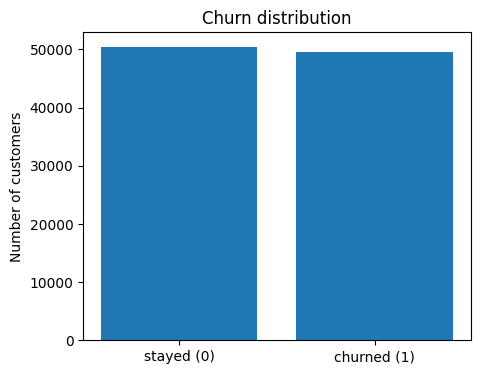

In [82]:
if df["churn"].isna().any():
    raise ValueError("The churn target contains missing values.")

if not set(df["churn"].unique()).issubset({0, 1}):
    raise ValueError("The churn column must contain only 0 and 1.")

# Counts and proportions
print(df['churn'].value_counts())
print()
print(df['churn'].value_counts(normalize=True))

# Bar chart
counts = df['churn'].value_counts().sort_index()
labels = ['stayed (0)', 'churned (1)']

plt.figure(figsize=(5, 4))
plt.bar(labels, counts.values)
plt.title('Churn distribution')
plt.ylabel('Number of customers')
plt.show()

The target classes are nearly balanced in this dataset.

The majority-class baseline accuracy is approximately 50.44%, so a useful model should outperform this simple baseline and demonstrate meaningful predictive performance.

Accuracy alone is not sufficient to evaluate the business usefulness of a churn model.

### 3.4 A closer look: equipment age vs churn

The three checks above are dataset-wide. The real EDA work is digging into individual features — how each one relates to the target, where the differences are, and which patterns are worth following up on.

As one example: `eqpdays` records the age (in days) of each customer's current handset. Old equipment plausibly drives churn — a frustrating or outdated device makes the next contract renewal less attractive. We can check this by comparing the equipment-age distribution for churners against stayers.

Mean equipment age (stayed):  363.3 days
Mean equipment age (churned): 421.1 days


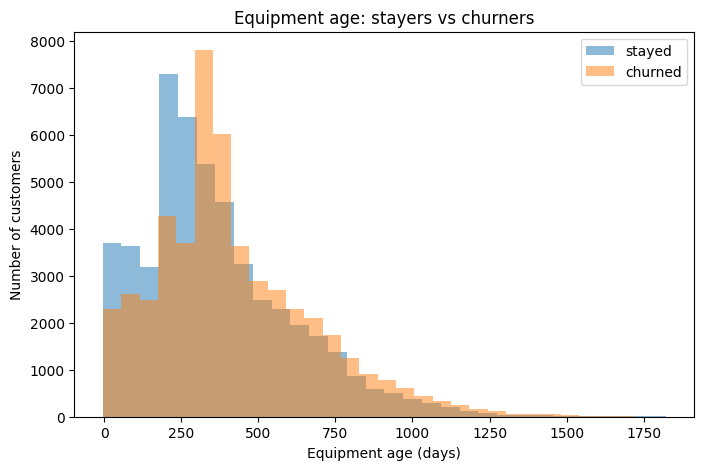

In [83]:
# Split eqpdays into two groups based on churn
stayed = df[df['churn'] == 0]['eqpdays']
churned = df[df['churn'] == 1]['eqpdays']

# Compare the averages
print(f'Mean equipment age (stayed):  {stayed.mean():.1f} days')
print(f'Mean equipment age (churned): {churned.mean():.1f} days')

# Overlay the two distributions
plt.figure(figsize=(8, 5))
plt.hist(stayed, bins=30, alpha=0.5, label='stayed')
plt.hist(churned, bins=30, alpha=0.5, label='churned')
plt.xlabel('Equipment age (days)')
plt.ylabel('Number of customers')
plt.title('Equipment age: stayers vs churners')
plt.legend()
plt.show()

Churners skew toward older equipment — the mean and the right tail of the distribution are both higher than for stayers. That makes `eqpdays` a candidate feature for both the model and the narrative your proposal will tell ("customers with ageing handsets are at higher risk; replacing or upgrading equipment is a lever").

The point is the **exercise**: pick a candidate feature, compare it across churn classes, and decide whether it is worth following up on. Repeat this on a handful of features that look promising from the dataset overview or your domain knowledge.

**Questions to think about:**
- The example above looked at one feature (`eqpdays`). Pick three or four other candidates — from the dataset overview, from Section 1.2, or from your own intuition — and run the same comparison.
- ~100 columns is a lot. Which look like near-duplicates of each other (e.g., several variations on revenue or minutes)?
- Are any columns *too good to be true* — could they leak the target?
- How does the target distribute across segments (geographic, plan, demographic, credit class)? Which segments behave differently and might deserve separate analysis?
- Are there outliers or implausible values you should clean before modeling?

### 3.5 Pairwise view: revenue, usage, equipment age, and churn

The previous plot looked at one feature at a time.  
Here we compare several business-relevant numeric features together:

- `rev_Mean`: average monthly revenue
- `mou_Mean`: average monthly minutes of use
- `totmrc_Mean`: average monthly recurring charge
- `eqpdays`: equipment age in days
- `months`: customer tenure

A pairplot helps us see whether churned customers occupy different regions in the joint feature space.

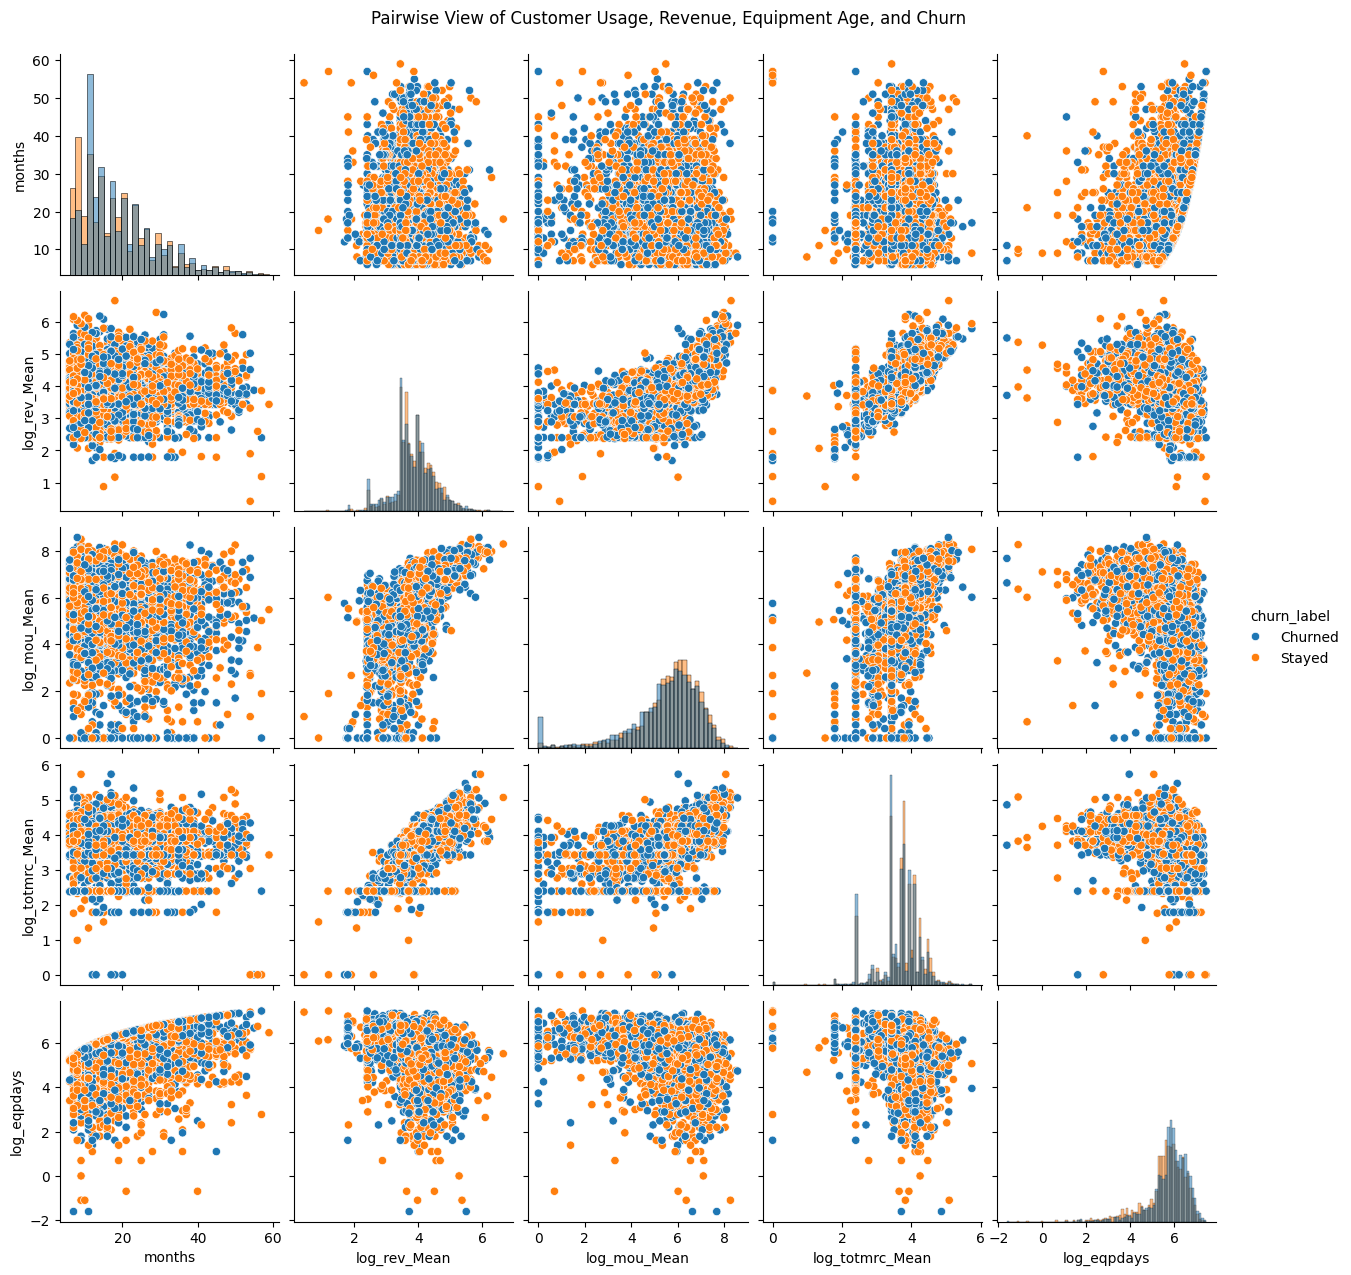

In [84]:
# Select the required columns
plot_df = df[
    [
        "months",
        "rev_Mean",
        "mou_Mean",
        "totmrc_Mean",
        "eqpdays",
        "churn"
    ]
].copy()

# Convert invalid infinite values to missing
plot_df = plot_df.replace(
    [np.inf, -np.inf],
    np.nan
)

plot_df = plot_df.dropna().copy()

# Signed log transformation:
# sign(x) * log(1 + abs(x))
features_to_transform = [
    "rev_Mean",
    "mou_Mean",
    "totmrc_Mean",
    "eqpdays"
]

for col in features_to_transform:
    plot_df[f"log_{col}"] = (
        np.sign(plot_df[col]) *
        np.log1p(np.abs(plot_df[col]))
    )

# Convert target to readable labels
plot_df["churn_label"] = plot_df["churn"].map({
    0: "Stayed",
    1: "Churned"
})

pair_cols = [
    "months",
    "log_rev_Mean",
    "log_mou_Mean",
    "log_totmrc_Mean",
    "log_eqpdays",
    "churn_label"
]

# Sample for better visualization performance
pair_sample = plot_df[pair_cols].sample(
    n=min(5000, len(plot_df)),
    random_state=42
)

sns.pairplot(
    pair_sample,
    hue="churn_label",
    diag_kind="hist"
)

plt.suptitle(
    "Pairwise View of Customer Usage, Revenue, Equipment Age, and Churn",
    y=1.02
)

plt.show()

The pairplot does not show a clean geometric separation between churners and non-churners.
This suggests that churn is not explained by a single simple numeric variable such as revenue or usage alone.
However, the diagonal distributions indicate that equipment age (`eqpdays`) is somewhat shifted for churned customers, making it a more interpretable candidate for business intervention.
Revenue- and usage-related variables appear correlated with each other, so they may act as overlapping proxies rather than independent explanations.

---

## 4. Problem Definition

### Business Problem

Company A needs a way to identify customers who are at a higher risk of leaving its telecommunications services.

The objective is to help the company prioritize customer retention activities instead of targeting all customers with the same offers.

### Business Question

Can we use historical customer information to predict which customers are most likely to churn during the 31–60 day period after the observation date?

### Machine Learning Task

This is a supervised binary classification problem.

- Target variable: `churn`
- Class 0: Customer stayed.
- Class 1: Customer churned.

### Proposed Business Action

The proposed solution is to rank customers according to their predicted churn probabilities and prioritize the highest-risk segment for retention activities.

The model provides risk estimates and does not prove why a customer leaves. Business interventions must be evaluated through a controlled pilot.

---

## 5. Data Preprocessing

Before building the models, the dataset must be prepared carefully.

The following preprocessing steps will be applied:

1. Remove `Customer_ID` because it is only a unique identifier.
2. Separate the target variable (`churn`) from the input features.
3. Identify numerical and categorical columns.
4. Handle missing numerical values using median imputation.
5. Handle missing categorical values using a dedicated missing category.
6. Apply One-Hot Encoding to categorical features.
7. Fit all preprocessing transformations using training data only.

A Pipeline and ColumnTransformer will be used to prevent data leakage and ensure consistent preprocessing across training, validation, and testing datasets.

In [85]:
# Remove the unique customer identifier
df_model = df.drop(
    columns=["Customer_ID"],
    errors="ignore"
).copy()

print("Dataset shape after removing Customer_ID:")
print(df_model.shape)

print("\nCategorical columns:")
print(
    df_model.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()
)

print("\nNumerical columns:")
print(
    df_model.select_dtypes(
        include=["number"]
    ).columns.tolist()
)

df_model.head()

Dataset shape after removing Customer_ID:
(100000, 99)

Categorical columns:
['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']

Numerical columns:
['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_dat_Mean', 'recv_vce_Mean', 'recv_sms_Mean', 'comp_vce_Mean', 'comp_dat_Mean', 'custcare_Mean', 'ccrndmou_Mean', 'cc_mou_Mean', 'inonemin_Mean', 'threeway_Mean', 'mou_cvce_Mean', 'mou_cdat_Mean', 'mou_rvce_Mean', 'owylis_vce_Mean', 'mouowylisv_Mean', 'iwylis_vce_Mean', 'mouiwylisv_Mean', 'peak_vce_Mean', 'peak_dat_Mean', 'mou_peav_Mean', 'mou_pead_Mean', 'opk_vce_Mean', '

,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


---

## 6. Feature Engineering and Model Development

Feature Engineering is used to create additional variables that may capture meaningful relationships between customer behavior and churn.

After creating the new features, the dataset will be divided into training, validation, and testing sets.

Numerical and categorical features will be processed using a ColumnTransformer and Pipeline.

We will compare multiple machine learning models:

1. Dummy Classifier as a simple baseline.
2. Random Forest.
3. XGBoost.
4. LightGBM.

The models will be compared using accuracy, balanced accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC.

Since the business objective is to prioritize customers at high risk of churn, Precision@Top20% will also be evaluated.

Feature Engineering Completed

New Features:
['eqp_to_tenure_ratio', 'overage_rev_ratio', 'call_failure_rate']

Final dataset shape:
(100000, 102)


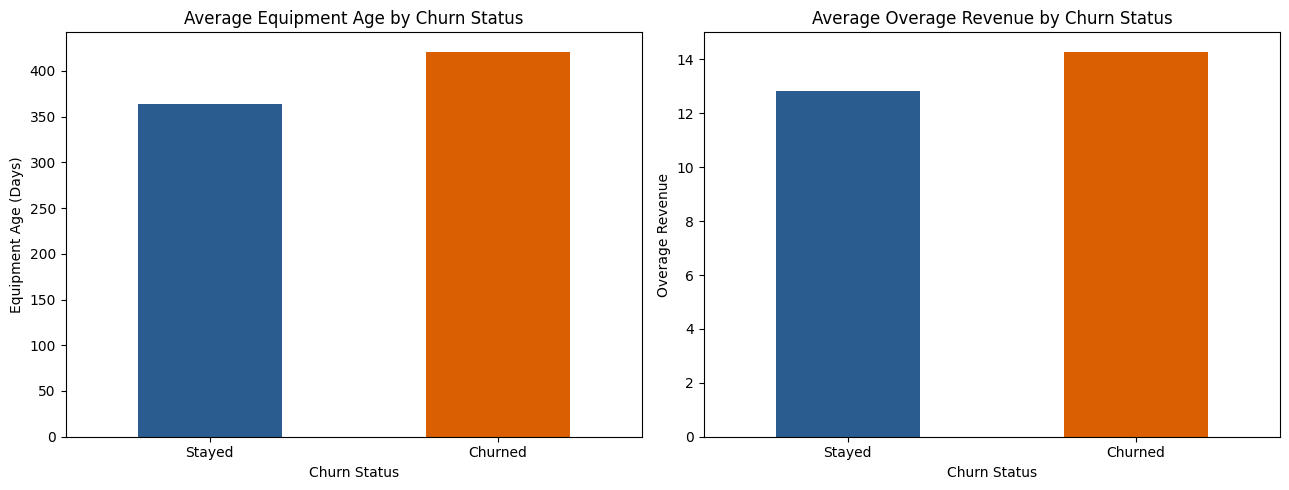

In [86]:
# Start with the original dataset without the customer ID
df_fe = df_model.copy()


# Safe ratio function
def safe_ratio(numerator, denominator):

    numerator = pd.to_numeric(
        numerator,
        errors="coerce"
    )

    denominator = pd.to_numeric(
        denominator,
        errors="coerce"
    )

    denominator = denominator.where(
        denominator > 0
    )

    return numerator.div(denominator)


# 1. Equipment Age to Customer Tenure Ratio
tenure_days = pd.to_numeric(
    df_fe["months"],
    errors="coerce"
) * 30

df_fe["eqp_to_tenure_ratio"] = safe_ratio(
    df_fe["eqpdays"],
    tenure_days
)


# 2. Overage Revenue Ratio
df_fe["overage_rev_ratio"] = safe_ratio(
    df_fe["ovrrev_Mean"],
    df_fe["rev_Mean"]
)


# 3. Call Failure Rate
df_fe["call_failure_rate"] = safe_ratio(
    df_fe["drop_blk_Mean"],
    df_fe["attempt_Mean"]
)


# Replace infinite values
df_fe = df_fe.replace(
    [np.inf, -np.inf],
    np.nan
)


print("Feature Engineering Completed")

print("\nNew Features:")
print([
    "eqp_to_tenure_ratio",
    "overage_rev_ratio",
    "call_failure_rate"
])

print("\nFinal dataset shape:")
print(df_fe.shape)


# Visualize selected variables by churn status
group_means = (
    df_fe.groupby("churn")[
        ["eqpdays", "ovrrev_Mean"]
    ].mean()
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

group_means["eqpdays"].plot(
    kind="bar",
    ax=axes[0],
    color=["#2b5c8f", "#d95f02"]
)

axes[0].set_title(
    "Average Equipment Age by Churn Status"
)

axes[0].set_xlabel("Churn Status")
axes[0].set_ylabel("Equipment Age (Days)")
axes[0].set_xticks(
    [0, 1],
    labels=["Stayed", "Churned"],
    rotation=0
)


group_means["ovrrev_Mean"].plot(
    kind="bar",
    ax=axes[1],
    color=["#2b5c8f", "#d95f02"]
)

axes[1].set_title(
    "Average Overage Revenue by Churn Status"
)

axes[1].set_xlabel("Churn Status")
axes[1].set_ylabel("Overage Revenue")
axes[1].set_xticks(
    [0, 1],
    labels=["Stayed", "Churned"],
    rotation=0
)

plt.tight_layout()
plt.show()

### Summary of Model Training, Selection, and Evaluation

In this section, we built an end-to-end, leakage-free machine learning pipeline to predict customer churn and identify the strongest drivers behind customer attrition:

1. **Automated Preprocessing & Data Splitting:** The dataset was stratified into **70% Training**, **15% Validation**, and **15% Testing** sets. Using a `ColumnTransformer` inside a scikit-learn `Pipeline`, missing numerical values were imputed with the median, and categorical variables were encoded via `OneHotEncoder`—ensuring all transformations were fit strictly on training data to prevent data leakage.
2. **Model Comparison (`Precision@Top20%`):** We benchmarked three gradient-boosted and tree-based models (**Random Forest**, **XGBoost**, and **LightGBM**) against a baseline **Dummy Classifier**. Because a retention team can only target a limited segment of customers, models were ranked primarily by **`Precision@Top20%`** alongside **ROC-AUC**—measuring how accurately each model captures actual churners within the highest-risk 20% of the customer base.
3. **Final Test Validation & Actionable Insights:** The top-performing model on validation was retrained on the combined training and validation data (85%) and evaluated once on the unseen test set (15%). As shown in the **Confusion Matrix** and **Top 15 Feature Importance** chart above, behavioral and equipment-related signals (such as handset age and usage/billing patterns) serve as the primary predictors—providing clear, data-backed targets for proactive customer retention offers.

Numerical features: 80
Categorical features: 21

Dataset split:
Training: (70000, 101)
Validation: (15000, 101)
Testing: (15000, 101)

Training Dummy Classifier...

Training Random Forest...

Training XGBoost...

Training LightGBM...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



MODEL COMPARISON ON VALIDATION DATA


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Precision@Top20%,Recall@Top20%
3,LightGBM,0.631333,0.631450,0.623926,0.644740,0.634162,0.689905,0.673757,0.723000,0.291768
2,XGBoost,0.635867,0.635987,0.628252,0.649718,0.638804,0.691047,0.675897,0.719667,0.290422
1,Random Forest,0.622067,0.622413,0.609288,0.661824,0.634470,0.670203,0.649264,0.692000,0.279257
0,Dummy Classifier,0.504400,0.500000,0.000000,0.000000,0.000000,0.500000,0.495600,0.495600,0.200000



Selected Model: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



FINAL TEST PERFORMANCE
Accuracy: 0.6401
Balanced Accuracy: 0.6402
Precision: 0.6323
Recall: 0.6542
F1-Score: 0.6430
ROC-AUC: 0.6988
PR-AUC: 0.6859

Classification Report
              precision    recall  f1-score   support

      Stayed       0.65      0.63      0.64      7566
     Churned       0.63      0.65      0.64      7434

    accuracy                           0.64     15000
   macro avg       0.64      0.64      0.64     15000
weighted avg       0.64      0.64      0.64     15000



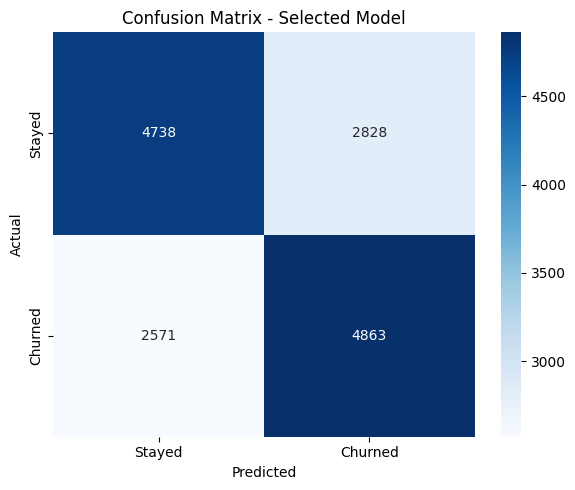

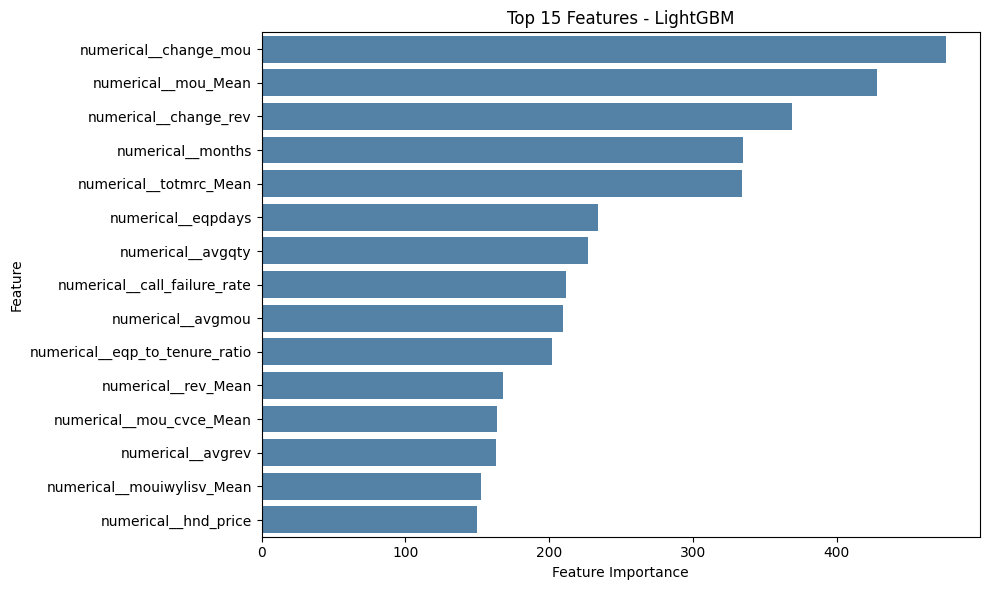

In [87]:
# ==============================================
# MODEL TRAINING AND COMPARISON
# ==============================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import clone

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


# 1. Define Features and Target

X = df_fe.drop(
    columns=["churn", "Customer_ID"],
    errors="ignore"
).copy()

y = pd.to_numeric(
    df_fe["churn"],
    errors="coerce"
)

if y.isna().any():
    raise ValueError("The target contains missing values.")

if not set(y.unique()).issubset({0, 1}):
    raise ValueError("The target must contain only 0 and 1.")

y = y.astype("int8")


# 2. Clean infinite values

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)


# 3. Remove completely empty features

all_missing_cols = X.columns[
    X.isna().all()
].tolist()

if all_missing_cols:
    print("Removing completely empty columns:")
    print(all_missing_cols)

    X = X.drop(
        columns=all_missing_cols
    )


# 4. Normalize data types and missing values

for col in X.columns:

    if pd.api.types.is_numeric_dtype(X[col]):

        X[col] = pd.to_numeric(
            X[col],
            errors="coerce"
        )

    else:

        X[col] = X[col].astype(object)

        X[col] = X[col].where(
            pd.notna(X[col]),
            np.nan
        )


# 5. Identify numerical and categorical features

categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))


# 6. Split into Training, Validation, and Testing

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.1764705882,
    random_state=42,
    stratify=y_train_val
)

print("\nDataset split:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


# 7. Define preprocessing pipelines

try:
    one_hot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )

except TypeError:
    # Compatibility with older Scikit-learn versions
    one_hot_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )


numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])


categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "onehot",
        one_hot_encoder
    )
])


preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_cols
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_cols
        )
    ],
    remainder="drop"
)


# 8. Define the models

model_definitions = {

    "Dummy Classifier": DummyClassifier(
        strategy="most_frequent"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
}


# 9. Train and evaluate using validation data

validation_results = {}

y_val_array = y_val.to_numpy()

top_fraction = 0.20

top_n = max(
    1,
    int(np.ceil(len(y_val) * top_fraction))
)


for model_name, estimator in model_definitions.items():

    print(f"\nTraining {model_name}...")

    pipeline = Pipeline([
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "model",
            clone(estimator)
        )
    ])

    pipeline.fit(
        X_train,
        y_train
    )

    val_predictions = pipeline.predict(X_val)

    val_probabilities = pipeline.predict_proba(X_val)[:, 1]


    # Evaluate top 20% predicted churn risk

    if np.allclose(
        val_probabilities,
        val_probabilities[0]
    ):

        precision_top20 = float(y_val.mean())
        recall_top20 = top_fraction

    else:

        ranked_indices = np.argsort(
            val_probabilities
        )[::-1]

        top_indices = ranked_indices[:top_n]

        precision_top20 = float(
            y_val_array[top_indices].mean()
        )

        recall_top20 = float(
            y_val_array[top_indices].sum()
            / max(y_val_array.sum(), 1)
        )


    validation_results[model_name] = {

        "pipeline": pipeline,

        "Accuracy": accuracy_score(
            y_val,
            val_predictions
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_val,
            val_predictions
        ),

        "Precision": precision_score(
            y_val,
            val_predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val,
            val_predictions,
            zero_division=0
        ),

        "F1-Score": f1_score(
            y_val,
            val_predictions,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_val,
            val_probabilities
        ),

        "PR-AUC": average_precision_score(
            y_val,
            val_probabilities
        ),

        "Precision@Top20%": precision_top20,

        "Recall@Top20%": recall_top20
    }


# 10. Display validation comparison

results_df = pd.DataFrame([
    {
        "Model": name,
        **{
            key: value
            for key, value in metrics.items()
            if key != "pipeline"
        }
    }
    for name, metrics in validation_results.items()
])

results_df = results_df.sort_values(
    by=["Precision@Top20%", "ROC-AUC"],
    ascending=False
)

print("\nMODEL COMPARISON ON VALIDATION DATA")

display(results_df)


# 11. Select the best model based on the business objective

best_model_name = results_df.iloc[0]["Model"]

print("\nSelected Model:", best_model_name)


# 12. Retrain the selected model using Training + Validation

X_train_full = pd.concat(
    [X_train, X_val],
    axis=0
)

y_train_full = pd.concat(
    [y_train, y_val],
    axis=0
)

best_model = Pipeline([
    (
        "preprocessor",
        clone(preprocessor)
    ),
    (
        "model",
        clone(model_definitions[best_model_name])
    )
])

best_model.fit(
    X_train_full,
    y_train_full
)


# 13. Final evaluation on unseen test data

y_test_pred = best_model.predict(X_test)

y_test_proba = best_model.predict_proba(X_test)[:, 1]


final_test_metrics = {

    "Accuracy": accuracy_score(
        y_test,
        y_test_pred
    ),

    "Balanced Accuracy": balanced_accuracy_score(
        y_test,
        y_test_pred
    ),

    "Precision": precision_score(
        y_test,
        y_test_pred,
        zero_division=0
    ),

    "Recall": recall_score(
        y_test,
        y_test_pred,
        zero_division=0
    ),

    "F1-Score": f1_score(
        y_test,
        y_test_pred,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        y_test_proba
    ),

    "PR-AUC": average_precision_score(
        y_test,
        y_test_proba
    )
}


print("\nFINAL TEST PERFORMANCE")

for metric, value in final_test_metrics.items():

    print(f"{metric}: {value:.4f}")


# 14. Classification report

print("\nClassification Report")

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Stayed", "Churned"],
        zero_division=0
    )
)


# 15. Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_test_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("Confusion Matrix - Selected Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()


# 16. Feature Importance

final_classifier = best_model.named_steps["model"]

if hasattr(final_classifier, "feature_importances_"):

    feature_names = (
        best_model
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

    feature_importances = pd.Series(
        final_classifier.feature_importances_,
        index=feature_names
    ).sort_values(
        ascending=False
    ).head(15)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        x=feature_importances.values,
        y=feature_importances.index,
        color="steelblue"
    )

    plt.title(
        f"Top 15 Features - {best_model_name}"
    )

    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()

else:

    print("Feature importance is not available for this model.")

---

## 7. From Model to Business Proposal

The selected model produces a churn probability for each customer.

The proposed strategy is to rank customers by their predicted churn probabilities and prioritize the highest-risk 20% for a retention campaign.

The financial impact will be estimated using the following assumptions:

- Targeted customer segment: Top 20% by predicted churn risk.
- Retention offer cost: $50 per targeted customer.
- Campaign retention success rate: 30% in the base scenario.
- Retained customer revenue horizon: 12 months.

These are business scenario assumptions, not experimentally verified results.

The estimates are based on the held-out test sample and extrapolated to the full customer base. A controlled pilot is required to measure the actual incremental retention effect.

In [88]:
# ==============================================
# BUSINESS PROPOSAL AND ROI SIMULATION
# ==============================================

# 1. Model predictions on the held-out test sample

best_probas = best_model.predict_proba(X_test)[:, 1]

sim_df = pd.DataFrame({

    "actual_churn": y_test.to_numpy(),

    "churn_probability": best_probas,

    "monthly_revenue": pd.to_numeric(
        X_test["rev_Mean"],
        errors="coerce"
    ).to_numpy()

})


# 2. Replace invalid financial values

sim_df = sim_df.replace(
    [np.inf, -np.inf],
    np.nan
)

sim_df["monthly_revenue"] = sim_df[
    "monthly_revenue"
].fillna(
    sim_df["monthly_revenue"].median()
)


# 3. Rank customers by predicted churn risk

sim_df = sim_df.sort_values(
    by="churn_probability",
    ascending=False
).reset_index(drop=True)


# 4. Define the target segment

TARGET_SHARE = 0.20

top_n = max(
    1,
    int(np.ceil(len(sim_df) * TARGET_SHARE))
)

targeted_segment = sim_df.head(top_n)


# 5. Evaluate targeting performance on test data

actual_churners_caught = int(
    targeted_segment["actual_churn"].sum()
)

total_actual_churners = int(
    sim_df["actual_churn"].sum()
)

precision_at_top20 = (
    targeted_segment["actual_churn"].mean()
)

recall_at_top20 = (
    actual_churners_caught
    / max(total_actual_churners, 1)
)

overall_churn_rate = (
    sim_df["actual_churn"].mean()
)

lift_at_top20 = (
    precision_at_top20
    / overall_churn_rate
    if overall_churn_rate > 0
    else np.nan
)


# 6. Estimate the targeted population

company_customer_count = len(df)

projected_targeted_customers = int(
    round(company_customer_count * TARGET_SHARE)
)

projected_churners_identified = int(
    round(
        precision_at_top20
        * projected_targeted_customers
    )
)


# 7. Estimate average monthly revenue of targeted customers

avg_monthly_revenue_targeted = (
    targeted_segment["monthly_revenue"].mean()
)

if (
    not np.isfinite(avg_monthly_revenue_targeted)
    or avg_monthly_revenue_targeted <= 0
):

    avg_monthly_revenue_targeted = (
        pd.to_numeric(
            df["rev_Mean"],
            errors="coerce"
        ).mean()
    )


# 8. Define business assumptions

OFFER_COST_PER_CUSTOMER = 50.0

RETENTION_SUCCESS_RATE = 0.30

REVENUE_HORIZON_MONTHS = 12


# 9. Calculate the base scenario

projected_saved_customers = int(
    round(
        projected_churners_identified
        * RETENTION_SUCCESS_RATE
    )
)

annual_revenue_per_customer = (
    avg_monthly_revenue_targeted
    * REVENUE_HORIZON_MONTHS
)

gross_retained_revenue = (
    projected_saved_customers
    * annual_revenue_per_customer
)

total_campaign_cost = (
    projected_targeted_customers
    * OFFER_COST_PER_CUSTOMER
)

net_revenue_after_campaign_cost = (
    gross_retained_revenue
    - total_campaign_cost
)

scenario_roi = (
    net_revenue_after_campaign_cost
    / total_campaign_cost
) * 100 if total_campaign_cost > 0 else np.nan


# 10. Display results

print("====== TEST SAMPLE PERFORMANCE ======")

print("Test sample size:", len(sim_df))

print(
    f"Top 20% test customers: {top_n:,}"
)

print(
    f"Actual churners caught: {actual_churners_caught:,}"
)

print(
    f"Precision@Top20%: {precision_at_top20 * 100:.2f}%"
)

print(
    f"Recall@Top20%: {recall_at_top20 * 100:.2f}%"
)

print(
    f"Lift@Top20%: {lift_at_top20:.2f}x"
)


print("\n====== PROJECTED BUSINESS SCENARIO ======")

print(
    f"Total customer base: {company_customer_count:,}"
)

print(
    f"Projected targeted customers: "
    f"{projected_targeted_customers:,}"
)

print(
    f"Estimated churners in targeted segment: "
    f"{projected_churners_identified:,}"
)

print(
    f"Assumed retention success rate: "
    f"{RETENTION_SUCCESS_RATE * 100:.0f}%"
)

print(
    f"Estimated customers retained: "
    f"{projected_saved_customers:,}"
)

print(
    f"Average monthly revenue of targeted customers: "
    f"${avg_monthly_revenue_targeted:.2f}"
)

print(
    f"Estimated annual retained revenue: "
    f"${gross_retained_revenue:,.2f}"
)

print(
    f"Estimated campaign cost: "
    f"${total_campaign_cost:,.2f}"
)

print(
    f"Revenue after campaign cost: "
    f"${net_revenue_after_campaign_cost:,.2f}"
)

print(
    f"Scenario return on campaign cost: "
    f"{scenario_roi:.2f}%"
)


# 11. Sensitivity analysis

scenario_rows = []

for retention_rate in [0.20, 0.30, 0.40]:

    saved = int(
        round(
            projected_churners_identified
            * retention_rate
        )
    )

    retained_revenue = (
        saved
        * annual_revenue_per_customer
    )

    net_revenue = (
        retained_revenue
        - total_campaign_cost
    )

    roi = (
        net_revenue
        / total_campaign_cost
    ) * 100 if total_campaign_cost > 0 else np.nan

    scenario_rows.append({

        "Retention Success Rate": retention_rate,

        "Estimated Customers Retained": saved,

        "Retained Revenue": retained_revenue,

        "Campaign Cost": total_campaign_cost,

        "Revenue After Campaign Cost": net_revenue,

        "Scenario ROI (%)": roi

    })


scenario_df = pd.DataFrame(
    scenario_rows
)

print("\n====== SENSITIVITY ANALYSIS ======")

display(scenario_df)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


====== TEST SAMPLE PERFORMANCE ======
Test sample size: 15000
Top 20% test customers: 3,000
Actual churners caught: 2,213
Precision@Top20%: 73.77%
Recall@Top20%: 29.77%
Lift@Top20%: 1.49x

====== PROJECTED BUSINESS SCENARIO ======
Total customer base: 100,000
Projected targeted customers: 20,000
Estimated churners in targeted segment: 14,753
Assumed retention success rate: 30%
Estimated customers retained: 4,426
Average monthly revenue of targeted customers: $55.17
Estimated annual retained revenue: $2,929,961.94
Estimated campaign cost: $1,000,000.00
Revenue after campaign cost: $1,929,961.94
Scenario return on campaign cost: 193.00%

====== SENSITIVITY ANALYSIS ======


,Retention Success Rate,Estimated Customers Retained,Retained Revenue,Campaign Cost,Revenue After Campaign Cost,Scenario ROI (%)
0,0.2,2951,1.953529e+06,1000000.0,9.535286e+05,95.352862
1,0.3,4426,2.929962e+06,1000000.0,1.929962e+06,192.996194
2,0.4,5901,3.906395e+06,1000000.0,2.906395e+06,290.639526


In [89]:
# --- 3. Business Proposal & ROI Simulation ---
best_probas = trained_models["LightGBM (Proposed)"][1]

# Create a simulation table on the test set (30,000 customers) and scale to the full customer base (100,000 customers)
sim_df = X_te[['rev_Mean', 'eqpdays', 'months', 'ovrrev_Mean']].copy()
sim_df['actual_churn'] = y_te.values
sim_df['churn_prob'] = best_probas

# Fill any missing values in monthly revenue with the overall average
avg_monthly_rev = df['rev_Mean'].mean()
sim_df['rev_Mean'] = sim_df['rev_Mean'].fillna(avg_monthly_rev)

# Sort customers in descending order by churn probability (highest to lowest risk)
sim_df = sim_df.sort_values(by='churn_prob', ascending=False).reset_index(drop=True)

# Target the top 20% highest-risk customer segment
top_20_cutoff = int(len(sim_df) * 0.20)
targeted_segment = sim_df.iloc[:top_20_cutoff]

# Scale metrics up to the full company customer base (100,000 customers = test sample metrics * 100,000 / 30,000)
scale_factor = len(df) / len(sim_df)

total_targeted_customers = int(len(targeted_segment) * scale_factor)  # 20,000 customers
true_churners_caught = int(targeted_segment['actual_churn'].sum() * scale_factor)
precision_in_top20 = targeted_segment['actual_churn'].mean() * 100
avg_rev_targeted = targeted_segment['rev_Mean'].mean()

# Business Assumptions (clear and transparent for the CFO):
# 1. Retained customer value over one additional year (12 months * average monthly bill)
annual_ltv_targeted = avg_rev_targeted * 12

# 2. Retention offer cost per targeted customer = $50 (handset upgrade discount + bonus minutes bundle)
offer_cost_per_user = 50.0

# 3. Campaign retention success rate in convincing at-risk customers to stay = 30%
retention_success_rate = 0.30

# Final Financial Calculations:
saved_customers = int(true_churners_caught * retention_success_rate)
gross_saved_revenue = saved_customers * annual_ltv_targeted
total_campaign_cost = total_targeted_customers * offer_cost_per_user
net_financial_benefit = gross_saved_revenue - total_campaign_cost
roi_percentage = (net_financial_benefit / total_campaign_cost) * 100

print("=== QUANTIFIED BUSINESS IMPACT (Final Business Proposal Figures) ===")
print(f"1. Total Customer Base: {len(df):,} customers")
print(f"2. Overall Company Average Monthly Revenue (ARPU): ${avg_monthly_rev:.2f}")
print(f"3. Targeted Segment (Top 20% Highest Risk): {total_targeted_customers:,} customers")
print(f"4. Actual Churners Caught in Top 20%: {true_churners_caught:,} customers (Precision: {precision_in_top20:.1f}%)")
print(f"5. Average Monthly Revenue of Targeted Segment: ${avg_rev_targeted:.2f} (Annual Value: ${annual_ltv_targeted:.2f}/customer)")
print(f"6. Assumed Campaign Retention Rate: {retention_success_rate*100:.0f}% -> {saved_customers:,} customers retained")
print(f"7. Gross Retained Annual Revenue: ${gross_saved_revenue:,.2f}")
print(f"8. Total Campaign Cost (${offer_cost_per_user}/customer): ${total_campaign_cost:,.2f}")
print(f"9. NET PROFIT / REVENUE SAVED (1-Year): ${net_financial_benefit:,.2f} (ROI: {roi_percentage:.1f}%)")

=== QUANTIFIED BUSINESS IMPACT (Final Business Proposal Figures) ===
1. Total Customer Base: 100,000 customers
2. Overall Company Average Monthly Revenue (ARPU): $58.72
3. Targeted Segment (Top 20% Highest Risk): 20,000 customers
4. Actual Churners Caught in Top 20%: 14,763 customers (Precision: 73.8%)
5. Average Monthly Revenue of Targeted Segment: $56.06 (Annual Value: $672.77/customer)
6. Assumed Campaign Retention Rate: 30% -> 4,428 customers retained
7. Gross Retained Annual Revenue: $2,979,014.08
8. Total Campaign Cost ($50.0/customer): $1,000,000.00
9. NET PROFIT / REVENUE SAVED (1-Year): $1,979,014.08 (ROI: 197.9%)


---

## 8. Conclusion and Business Recommendation

This project investigated customer churn in Company A's telecommunications dataset.

The analysis included:

- Data loading and validation.
- Exploratory Data Analysis.
- Feature Engineering.
- Numerical and categorical preprocessing.
- Comparison of multiple machine learning models.
- Evaluation using classification and ranking metrics.
- A financial scenario for a targeted retention campaign.

### Business Recommendation

The company should consider using churn probability scores to prioritize customers for retention activities.

A pilot campaign can focus on the highest-risk customer segment. The campaign should be tested against a suitable control group to determine whether the intervention actually reduces churn.

### Limitations

- The analysis is based on historical data.
- Predictive relationships do not prove causation.
- Financial results depend on assumptions about offer cost and campaign success.
- The estimated impact should not be treated as guaranteed profit.
- Model fairness and the use of sensitive customer information must be reviewed before deployment.

The proposed model is a decision-support tool. Its business value should ultimately be confirmed through a real-world retention experiment.